# Sensitivity of the scattering matrix and efficiency factors of marine particles

Sensitivity of the efficiency factors ($Q_{ext}$, $Q_{abs}$, $Q_{bb}$), single scattering albedo,
asymmetry parameter and scattering matrix of homogeneous spheres to:

* the real part of the refractive index, $m_r$ = 1.02 to 1.20,
* four spectral shapes of the imaginary part $m_i(\lambda)$,
* eight size distributions of particles with radius $r \le 40$ µm (power-law and log-normal).

**Assumptions**

* The refractive index is relative to seawater, $n_w = 1.34$. Since MOPSMAP has no
  surrounding-medium option, the computations use the wavelength in water $\lambda / n_w$:
  the efficiency factors and the normalized scattering matrix only depend on the size
  parameter $x = 2\pi r n_w / \lambda$ and on the relative refractive index.
* Wavelengths are the Sentinel-3/OLCI bands from 400 to 900 nm (in vacuum).

**Methods**

* MOPSMAP (Gasteiger and Wiegner, 2018) for $m_r$ = 1.04, 1.08, 1.12, 1.16, 1.20: these are
  nodes of the MOPSMAP sphere dataset (size parameter up to 1013, here $x \le 843$).
* Exact Mie computations (`miepython`) for $m_r$ = 1.02. MOPSMAP interpolates linearly in $m_r$
  between the dataset nodes 1.00 (no scattering) and 1.04, which underestimates the scattering
  of large particles at 1.02 by about a factor of 2.
* Both codes share the same radius grid and size distributions, and the Mie computations are
  cross-checked against MOPSMAP at $m_r$ = 1.04 (section 4).

The MOPSMAP runs (external program) are computed in parallel with Dask's threaded scheduler, and
the Mie computations (pure Python, GIL-bound) with Dask's processes scheduler.

**Requirements**: MOPSMAP installation (set `MOPSMAP_DIR`), `pip install -e .` from the
repository root and `pip install miepython`. The full run takes about 11 minutes on 40 CPUs, mostly
for the exact Mie computations.

## 1. Setup

In [1]:
import os
os.environ.setdefault('MOPSMAP_DIR', '/data/vrtc/aerosol/mopsmap')

from pathlib import Path

import time

import dask
import matplotlib.pyplot as plt
import miepython
import numpy as np
import pandas as pd
import xarray as xr

from mopsmap_tbx.opac_mopsmap import MOPSMAP_DATA, ROOT, compute_tasks, run_mopsmap

odir = ROOT / 'scatmat' / 'sensitivity'
idir = odir / 'inputs'
idir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.size': 11, 'axes.titlesize': 11, 'axes.labelsize': 11, 'legend.fontsize': 9,
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'lines.linewidth': 1.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.dpi': 100, 'savefig.dpi': 200,
})
# ordinal ramp for m_r (MOPSMAP nodes), m_r = 1.02 (Mie) is drawn dashed in orange
MR_COLORS = ['#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b']
MIE_COLOR = '#eb6834'
PSD_COLORS = ['#86b6ef', '#3987e5', '#1c5cab', '#0d366b']
SHAPE_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
print('MOPSMAP:', os.environ['MOPSMAP_DIR'], '| miepython', miepython.__version__, '| dask', dask.__version__)

MOPSMAP: /data/vrtc/aerosol/mopsmap | miepython 3.1.0 | dask 2024.8.0


In [2]:
n_w = 1.34                                   # refractive index of seawater
wl = np.array([400, 412.5, 442.5, 490, 510, 560, 620, 665, 673.75, 681.25,
               708.75, 753.75, 778.75, 865, 885, 900])  # OLCI bands (nm, vacuum)
wl_w = wl * 1e-3 / n_w                       # wavelength in water (µm)

mr_mopsmap = [1.04, 1.08, 1.12, 1.16, 1.20]  # MOPSMAP dataset nodes
mr_mie = [1.02]                              # exact Mie
mr_all = mr_mie + mr_mopsmap

r_min, r_max = 0.05, 40.                     # radius range (µm)
r = np.logspace(np.log10(r_min), np.log10(r_max), 1200)
theta = np.loadtxt(Path(MOPSMAP_DATA) / 'scat_angle_grid.txt')
mu = np.cos(np.radians(theta))

print(f'{len(wl)} wavelengths, {len(r)} radii, {len(theta)} scattering angles')
print(f'max size parameter: {2 * np.pi * r_max / wl_w.min():.0f} (MOPSMAP dataset: 1013)')

16 wavelengths, 1200 radii, 376 scattering angles
max size parameter: 842 (MOPSMAP dataset: 1013)


## 2. Size distributions

Number size distributions $n(r) = dN/dr$ between 0.05 and 40 µm, normalized to one particle:

* power law (Junge) $n(r) \propto r^{-\xi}$ with $\xi$ = 3, 3.5, 4, 4.5,
* log-normal $n(r) \propto \frac{1}{r} \exp\left[-\frac{1}{2}\left(\frac{\ln(r/r_{mod})}{\ln \sigma}\right)^2\right]$
  with $r_{mod}$ = 0.5, 1, 2, 5 µm and $\sigma$ = 1.8.

The same tabulated $n(r)$ is given to MOPSMAP (`size distr_file dndr`) and used for the Mie
integration. The cross-section-weighted size distribution $dA/d\ln r \propto r^3 n(r)$ shows which
particles dominate the optical properties.

In [3]:
def junge(r, xi):
    return r ** -xi


def lognormal(r, r_mod, sigma):
    return np.exp(-0.5 * (np.log(r / r_mod) / np.log(sigma)) ** 2) / r


psd_def = {
    'J3.0': ('Junge', 'ξ = 3.0', junge(r, 3.0)),
    'J3.5': ('Junge', 'ξ = 3.5', junge(r, 3.5)),
    'J4.0': ('Junge', 'ξ = 4.0', junge(r, 4.0)),
    'J4.5': ('Junge', 'ξ = 4.5', junge(r, 4.5)),
    'LN0.5': ('log-normal', 'r_mod = 0.5 µm', lognormal(r, 0.5, 1.8)),
    'LN1': ('log-normal', 'r_mod = 1 µm', lognormal(r, 1., 1.8)),
    'LN2': ('log-normal', 'r_mod = 2 µm', lognormal(r, 2., 1.8)),
    'LN5': ('log-normal', 'r_mod = 5 µm', lognormal(r, 5., 1.8)),
}
psd_ids = list(psd_def)
dr = np.gradient(r)
n_r = np.array([v[2] / np.sum(v[2] * dr) for v in psd_def.values()])  # dN/dr, N = 1
weights = n_r * dr                                                    # (psd, r) quadrature weights

reff = (weights @ r ** 3) / (weights @ r ** 2)
pd.DataFrame({'family': [v[0] for v in psd_def.values()], 'parameter': [v[1] for v in psd_def.values()],
              'r_eff (µm)': reff.round(3)}, index=psd_ids)

,family,parameter,r_eff (µm)
J3.0,Junge,ξ = 3.0,5.988
J3.5,Junge,ξ = 3.5,1.414
J4.0,Junge,ξ = 4.0,0.334
J4.5,Junge,ξ = 4.5,0.144
LN0.5,log-normal,r_mod = 0.5 µm,1.186
LN1,log-normal,r_mod = 1 µm,2.372
LN2,log-normal,r_mod = 2 µm,4.742
LN5,log-normal,r_mod = 5 µm,11.517


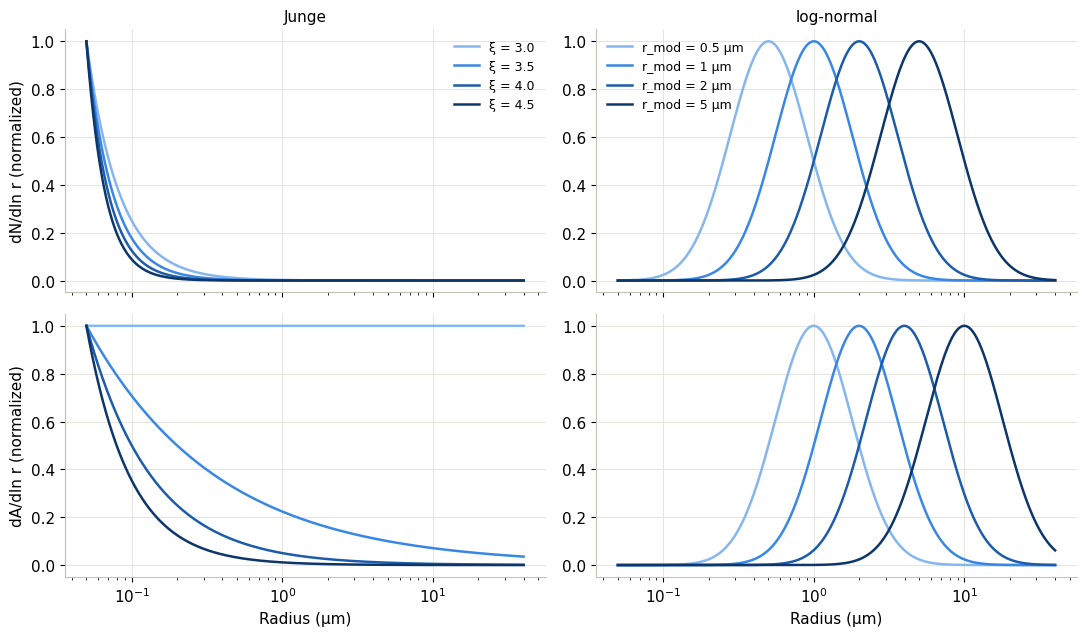

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for i, fam in enumerate(['Junge', 'log-normal']):
    ids = [p for p in psd_ids if psd_def[p][0] == fam]
    for p, c in zip(ids, PSD_COLORS):
        k = psd_ids.index(p)
        dndlnr = n_r[k] * r
        dadlnr = n_r[k] * r ** 3
        axs[0, i].plot(r, dndlnr / dndlnr.max(), color=c, label=psd_def[p][1])
        axs[1, i].plot(r, dadlnr / dadlnr.max(), color=c, label=psd_def[p][1])
    axs[0, i].set_title(fam)
    axs[0, i].legend(frameon=False)
for ax in axs.ravel():
    ax.set_xscale('log')
axs[0, 0].set_ylabel('dN/dln r (normalized)')
axs[1, 0].set_ylabel('dA/dln r (normalized)')
for ax in axs[1]:
    ax.set_xlabel('Radius (µm)')
plt.tight_layout()

## 3. Spectral imaginary part

Four spectral shapes of $m_i(\lambda)$ relative to seawater (illustrative magnitudes of marine particles):

* `none`: non-absorbing particles,
* `flat`: spectrally neutral absorption, $m_i = 5 \times 10^{-4}$,
* `exponential`: non-algal / mineral-like, $m_i = 2 \times 10^{-3} \exp[-0.011(\lambda - 442.5)]$,
* `pigment`: phytoplankton-like with chlorophyll bands at 442.5 and 675 nm,
  $m_i = 2 \times 10^{-4} + 3 \times 10^{-3} \, G(442.5, 35) + 1.5 \times 10^{-3} \, G(675, 15)$
  with $G(\lambda_0, s) = \exp[-\frac{1}{2}((\lambda - \lambda_0)/s)^2]$.

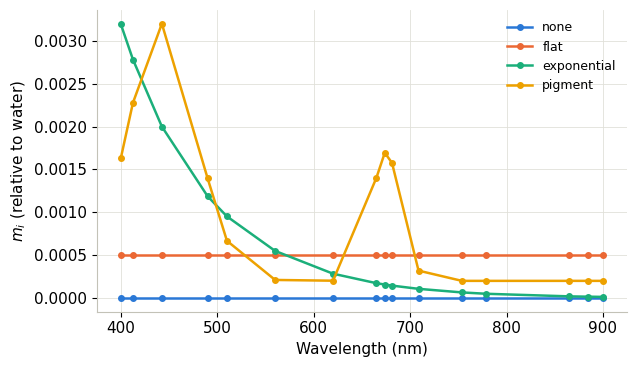

In [5]:
def gauss(lam, lam0, s):
    return np.exp(-0.5 * ((lam - lam0) / s) ** 2)


mi_def = {
    'none': np.zeros_like(wl),
    'flat': np.full_like(wl, 5e-4),
    'exponential': 2e-3 * np.exp(-0.011 * (wl - 442.5)),
    'pigment': 2e-4 + 3e-3 * gauss(wl, 442.5, 35) + 1.5e-3 * gauss(wl, 675, 15),
}
shapes = list(mi_def)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for s, c in zip(shapes, SHAPE_COLORS):
    ax.plot(wl, mi_def[s], 'o-', ms=4, color=c, label=s)
ax.set_xlabel('Wavelength (nm)')
ax.set_ylabel('$m_i$ (relative to water)')
ax.legend(frameon=False)
plt.tight_layout()

## 4. Computations

### MOPSMAP ($m_r$ = 1.04 to 1.20)

One MOPSMAP run per ($m_r$, $m_i$ shape, size distribution) for all wavelengths: the refractive
index file gives the wavelengths (`wavelength from_refrac_file`). The integrated output gives the
extinction coefficient and the particle cross section per volume, whose ratio is $Q_{ext}$, and
the scattering matrix elements $a_1, a_2, a_3, a_4, b_1, b_2$ normalized so that
$\frac{1}{2}\int_0^\pi a_1 \sin\theta \, d\theta = 1$.

In [6]:
MOPSMAP_INPUT = '''mode 1 size distr_file dndr '{psd}'
mode 1 refrac file '{refr}'
mode 1 shape sphere
wavelength from_refrac_file
scatlib '{data}/optical_dataset'
output integrated
output scattering_matrix
output theta_file '{data}/scat_angle_grid.txt'
output digits 10
'''

for k, p in enumerate(psd_ids):
    np.savetxt(idir / f'psd_{p}.txt', np.c_[r, n_r[k]], fmt='%.8e')
for mr in mr_mopsmap:
    for s in shapes:
        np.savetxt(idir / f'refr_{mr:.2f}_{s}.txt', np.c_[wl_w, np.full_like(wl_w, mr), mi_def[s]], fmt='%.8e')


@dask.delayed
def mopsmap_case(psd_file, refr_file):
    # MOPSMAP returns Qext, ssa, g (wl,) and the scattering matrix (wl, theta, element)
    out = run_mopsmap(MOPSMAP_INPUT.format(psd=psd_file, refr=refr_file, data=MOPSMAP_DATA))
    integ = np.array([l.split()[1:] for l in out.splitlines() if l.startswith('integrated')], float)
    if len(integ) != len(wl_w):
        raise RuntimeError(f'MOPSMAP failed for {psd_file}, {refr_file}:\n{out[-2000:]}')
    sm = np.array([l.split()[3:9] for l in out.splitlines() if l.startswith('scattering_matrix')], float)
    return integ[:, 1] / integ[:, 6], integ[:, 2], integ[:, 3], sm.reshape(len(wl_w), len(theta), 6)


keys = [(mr, s, p) for mr in mr_mopsmap for s in shapes for p in psd_ids]
tasks = [mopsmap_case(idir / f'psd_{p}.txt', idir / f'refr_{mr:.2f}_{s}.txt') for mr, s, p in keys]
print(len(tasks), 'MOPSMAP runs')
t0 = time.perf_counter()
res_mopsmap = compute_tasks(tasks, progress=False)
print(f'done in {time.perf_counter() - t0:.0f} s')

160 MOPSMAP runs


done in 13 s


### Exact Mie ($m_r$ = 1.02, and 1.04 for the cross-check)

One Dask task per ($m_r$, $m_i$, wavelength): the amplitude functions $S_1, S_2$ are computed for
the 1200 radii and directly integrated over the eight size distributions in the worker, so that only
the size-averaged results are sent back. With the Bohren and Huffman (1983) elements
$S_{11} = (|S_2|^2 + |S_1|^2)/2$, $S_{12} = (|S_2|^2 - |S_1|^2)/2$, $S_{33} = \mathrm{Re}(S_2 S_1^*)$,
$S_{34} = \mathrm{Im}(S_2 S_1^*)$, the MOPSMAP elements of spheres are
$a_1 = a_2 \propto \langle S_{11} \rangle$, $a_3 = a_4 \propto \langle S_{33} \rangle$,
$b_1 \propto \langle S_{12} \rangle$ and $b_2 \propto -\langle S_{34} \rangle$, normalized by
$\langle x^2 Q_{sca} \rangle$ (with the `bohren` normalization of `miepython`,
$\int (|S_1|^2 + |S_2|^2)/2 \, d\Omega = 4\pi x^2 Q_{sca}$).

In [7]:
@dask.delayed
def mie_case(mr, mi, wl_w, r, mu, weights):
    # size-averaged Qext, ssa, g (psd,) and scattering matrix (psd, theta, element) for one wavelength
    import miepython
    import numpy as np

    m = complex(mr, -mi)
    x = 2 * np.pi * r / wl_w
    qext, qsca, _, g = miepython.efficiencies_mx(m, x)
    S11, S12, S33, S34 = (np.empty((len(x), len(mu))) for _ in range(4))
    for i, xi in enumerate(x):
        S1, S2 = miepython.S1_S2(m, xi, mu, norm='bohren')
        S11[i] = (np.abs(S2) ** 2 + np.abs(S1) ** 2) / 2
        S12[i] = (np.abs(S2) ** 2 - np.abs(S1) ** 2) / 2
        S33[i] = np.real(S2 * np.conj(S1))
        S34[i] = np.imag(S2 * np.conj(S1))
    G = np.pi * r ** 2
    Qext = weights @ (G * qext) / (weights @ G)
    Qsca = weights @ (G * qsca) / (weights @ G)
    gg = weights @ (G * qsca * g) / (weights @ (G * qsca))
    den = (weights @ (x ** 2 * qsca))[:, None]
    a1, a3 = weights @ S11 / den, weights @ S33 / den
    b1, b2 = weights @ S12 / den, -(weights @ S34) / den
    return Qext, Qsca / Qext, gg, np.stack([a1, a1, a3, a3, b1, b2], axis=-1)


mie_keys = [(mr, s) for mr in mr_mie for s in shapes] + [(1.04, 'none'), (1.04, 'pigment')]
tasks = [mie_case(mr, mi_def[s][iw], wl_w[iw], r, mu, weights) for mr, s in mie_keys for iw in range(len(wl))]
print(len(tasks), 'Mie tasks')
t0 = time.perf_counter()
res_mie = dask.compute(*tasks, scheduler='processes', num_workers=os.cpu_count())
print(f'done in {time.perf_counter() - t0:.0f} s')

96 Mie tasks


done in 648 s


### Gathering the results in an xarray Dataset

In [8]:
elements = ['a1', 'a2', 'a3', 'a4', 'b1', 'b2']
dims = ('wl', 'psd')
coords = dict(wl=wl, psd=psd_ids, theta=theta, element=elements, shape=shapes)


def to_dataset(Qext, ssa, g, F, mr, shapes_):
    # arrays (mr, shape, wl, psd) and (mr, shape, wl, psd, theta, element)
    c = dict(coords, mr=mr, shape=shapes_)
    d4 = ('mr', 'shape', 'wl', 'psd')
    return xr.Dataset({'Qext': (d4, Qext), 'ssa': (d4, ssa), 'g': (d4, g),
                       'F': (d4 + ('theta', 'element'), F)}, coords=c)


# MOPSMAP: results ordered as (mr, shape, psd) with arrays over wl
shp = (len(mr_mopsmap), len(shapes), len(psd_ids))
Qext, ssa, g, F = (np.array([res[i] for res in res_mopsmap]).reshape(shp + np.shape(res_mopsmap[0][i]))
                   for i in range(4))
ds_mopsmap = to_dataset(Qext.transpose(0, 1, 3, 2), ssa.transpose(0, 1, 3, 2), g.transpose(0, 1, 3, 2),
                        F.transpose(0, 1, 3, 2, 4, 5), mr_mopsmap, shapes)


# Mie: results ordered as (mr, shape, wl) with arrays over psd
def mie_dataset(keys, res):
    mrs = sorted(set(k[0] for k in keys))
    shapes_ = [s for s in shapes if any(k[1] == s for k in keys)]
    out = []
    for mr in mrs:
        sub = []
        for s in shapes_:
            i0 = keys.index((mr, s)) * len(wl)
            block = res[i0:i0 + len(wl)]
            sub.append(to_dataset(*[np.array([b[i] for b in block])[None, None] for i in range(4)], [mr], [s]))
        out.append(xr.concat(sub, 'shape'))
    return xr.concat(out, 'mr')


n1 = len(mr_mie) * len(shapes) * len(wl)
ds_mie = mie_dataset(mie_keys[:len(mr_mie) * len(shapes)], res_mie[:n1])
ds_check = mie_dataset(mie_keys[len(mr_mie) * len(shapes):], res_mie[n1:])

ds = xr.concat([ds_mie, ds_mopsmap], 'mr')
ds = ds.assign_coords(method=('mr', ['Mie'] * len(mr_mie) + ['MOPSMAP'] * len(mr_mopsmap)))


def add_derived(ds):
    # absorption and backscattering efficiencies, backscattering ratio and degree of linear polarization
    ds = ds.assign_coords(theta_rad=('theta', np.radians(ds.theta.values)))
    a1s = ds.F.sel(element='a1') * np.sin(ds.theta_rad)
    back = a1s.where(ds.theta >= 90, drop=True).integrate('theta_rad')
    ds['bb_ratio'] = back / a1s.integrate('theta_rad')
    ds['Qsca'] = ds.Qext * ds.ssa
    ds['Qabs'] = ds.Qext - ds.Qsca
    ds['Qbb'] = ds.Qsca * ds.bb_ratio
    ds['dolp'] = -ds.F.sel(element='b1') / ds.F.sel(element='a1')
    return ds


ds = add_derived(ds)
ds_check = add_derived(ds_check)
ds_ref = add_derived(ds_mopsmap.sel(mr=[1.04], shape=ds_check.shape))
ds

<xarray.Dataset> Size: 65MB
Dimensions:    (mr: 6, shape: 4, wl: 16, psd: 8, theta: 376, element: 6)
Coordinates:
  * wl         (wl) float64 128B 400.0 412.5 442.5 490.0 ... 865.0 885.0 900.0
  * psd        (psd) <U5 160B 'J3.0' 'J3.5' 'J4.0' 'J4.5' ... 'LN1' 'LN2' 'LN5'
  * theta      (theta) float64 3kB 0.0 0.001 0.005 0.01 ... 179.0 179.5 180.0
  * element    (element) <U2 48B 'a1' 'a2' 'a3' 'a4' 'b1' 'b2'
  * shape      (shape) <U11 176B 'none' 'flat' 'exponential' 'pigment'
  * mr         (mr) float64 48B 1.02 1.04 1.08 1.12 1.16 1.2
    method     (mr) <U7 168B 'Mie' 'MOPSMAP' 'MOPSMAP' ... 'MOPSMAP' 'MOPSMAP'
    theta_rad  (theta) float64 3kB 0.0 1.745e-05 8.727e-05 ... 3.124 3.133 3.142
Data variables:
    Qext       (mr, shape, wl, psd) float64 25kB 1.092 0.3575 ... 2.225 2.109
    ssa        (mr, shape, wl, psd) float64 25kB 1.0 1.0 1.0 ... 0.9863 0.9691
    g          (mr, shape, wl, psd) float64 25kB 0.9967 0.9947 ... 0.8872 0.9121
    F          (mr, shape, wl, psd, theta, element) float64 55MB 5.22e+04 ......
    bb_ratio   (mr, shape, wl, psd) float64 25kB 0.0001713 0.0004448 ... 0.02717
    Qsca       (mr, shape, wl, psd) float64 25kB 1.092 0.3575 ... 2.195 2.044
    Qabs       (mr, shape, wl, psd) float64 25kB 0.0 0.0 0.0 ... 0.0306 0.06525
    Qbb        (mr, shape, wl, psd) float64 25kB 0.0001871 0.000159 ... 0.05554
    dolp       (mr, shape, wl, psd, theta) float64 9MB -0.0 -1.848e-09 ... -0.0

### Cross-check: exact Mie vs MOPSMAP at $m_r$ = 1.04

Maximum relative difference over the 16 wavelengths for the non-absorbing and `pigment` cases
(the latter also tests the interpolation of MOPSMAP in $m_i$).

In [9]:
vars_ = ['Qext', 'Qabs', 'ssa', 'g', 'bb_ratio']
diff = {v: (100 * np.abs(ds_check[v] / ds_ref[v] - 1)).max('wl').squeeze('mr') for v in vars_}
table = pd.concat({v: d.to_pandas().T for v, d in diff.items()}, axis=1)
table.dropna(axis=1, how='all').round(2)  # Qabs = 0 for non-absorbing particles

Qext            Qabs  ssa             g         bb_ratio        
shape  none pigment pigment none pigment  none pigment     none pigment
psd                                                                    
J3.0   0.03    0.02   14.10  0.0    0.53  0.00    0.01     1.09    4.16
J3.5   0.13    0.13    9.21  0.0    0.24  0.00    0.00     0.45    1.08
J4.0   0.28    0.28    3.65  0.0    0.09  0.00    0.00     0.26    0.24
J4.5   0.42    0.41    0.65  0.0    0.08  0.01    0.01     0.33    0.34
LN0.5  0.01    0.01    1.23  0.0    0.03  0.00    0.00     0.01    0.05
LN1    0.01    0.01    2.45  0.0    0.05  0.00    0.00     0.00    0.18
LN2    0.00    0.01    4.83  0.0    0.11  0.00    0.00     0.11    0.73
LN5    0.00    0.00   11.00  0.0    0.47  0.00    0.01     0.88    3.13

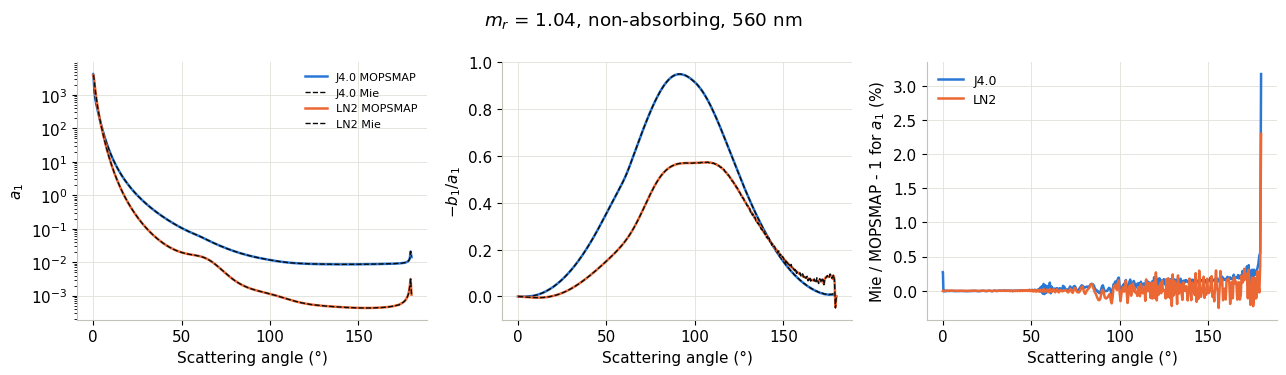

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for p, c in zip(['J4.0', 'LN2'], ['#2a78d6', '#eb6834']):
    a = ds_ref.sel(mr=1.04, shape='none', psd=p, wl=560)
    b = ds_check.sel(mr=1.04, shape='none', psd=p, wl=560)
    axs[0].plot(a.theta, a.F.sel(element='a1'), color=c, label=f'{p} MOPSMAP')
    axs[0].plot(b.theta, b.F.sel(element='a1'), '--', color='#0b0b0b', lw=1, label=f'{p} Mie')
    axs[1].plot(a.theta, a.dolp, color=c, label=f'{p} MOPSMAP')
    axs[1].plot(b.theta, b.dolp, '--', color='#0b0b0b', lw=1, label=f'{p} Mie')
    axs[2].plot(a.theta, 100 * (b.F.sel(element='a1') / a.F.sel(element='a1') - 1), color=c, label=p)
axs[0].set_yscale('log')
axs[0].set_ylabel('$a_1$')
axs[1].set_ylabel('$-b_1/a_1$')
axs[2].set_ylabel('Mie / MOPSMAP - 1 for $a_1$ (%)')
axs[0].legend(frameon=False, fontsize=8)
axs[2].legend(frameon=False)
for ax in axs:
    ax.set_xlabel('Scattering angle (°)')
fig.suptitle('$m_r$ = 1.04, non-absorbing, 560 nm')
plt.tight_layout()

## 5. Sensitivity analysis

$Q_{ext}$, single scattering albedo and $g$ agree within 0.5 %, the backscattering ratio within about
1 % for non-absorbing particles (4 % in the `pigment` case), and the phase function within 0.5 % except
near 180°. However $Q_{abs}$ differs by up to 14 % in the `pigment` case. The
differences are at the weakly absorbing wavelengths, where $0 < m_i < 5.4 \times 10^{-4}$, the first
non-zero $m_i$ node of the MOPSMAP dataset: MOPSMAP interpolates linearly in $m_i$ while the
absorption of large particles is not linear in $m_i$. MOPSMAP therefore underestimates $Q_{abs}$ of
weakly absorbing large particles, as shown below.

In [11]:
# Mie / MOPSMAP - 1 (%) for Qabs, pigment case
qabs = (100 * (ds_check.Qabs / ds_ref.Qabs - 1)).sel(shape='pigment', mr=1.04).to_pandas().round(1)
qabs.insert(0, 'm_i', mi_def['pigment'].round(5))
qabs

psd,m_i,J3.0,J3.5,J4.0,J4.5,LN0.5,LN1,LN2,LN5
wl,,,,,,,,,
400.00,0.00164,0.5,0.3,-0.0,-0.2,0.2,0.3,0.4,0.5
412.50,0.00228,0.4,0.2,-0.1,-0.2,0.2,0.3,0.4,0.4
442.50,0.00320,0.3,0.2,-0.1,-0.2,0.2,0.3,0.4,0.4
490.00,0.00139,0.6,0.3,-0.0,-0.2,0.1,0.2,0.3,0.6
510.00,0.00067,2.2,1.4,0.4,-0.1,0.3,0.6,1.0,1.9
560.00,0.00021,14.1,9.2,3.6,0.6,1.2,2.4,4.8,11.0
620.00,0.00020,13.2,8.7,3.4,0.6,1.1,2.3,4.5,10.3
665.00,0.00140,0.6,0.3,-0.1,-0.2,0.1,0.1,0.3,0.5
673.75,0.00169,0.7,0.4,-0.0,-0.2,0.1,0.2,0.4,0.6


### Spectral efficiency factors

`pigment` absorption, for a steep power law ($\xi$ = 4) and the 2 µm log-normal distribution.

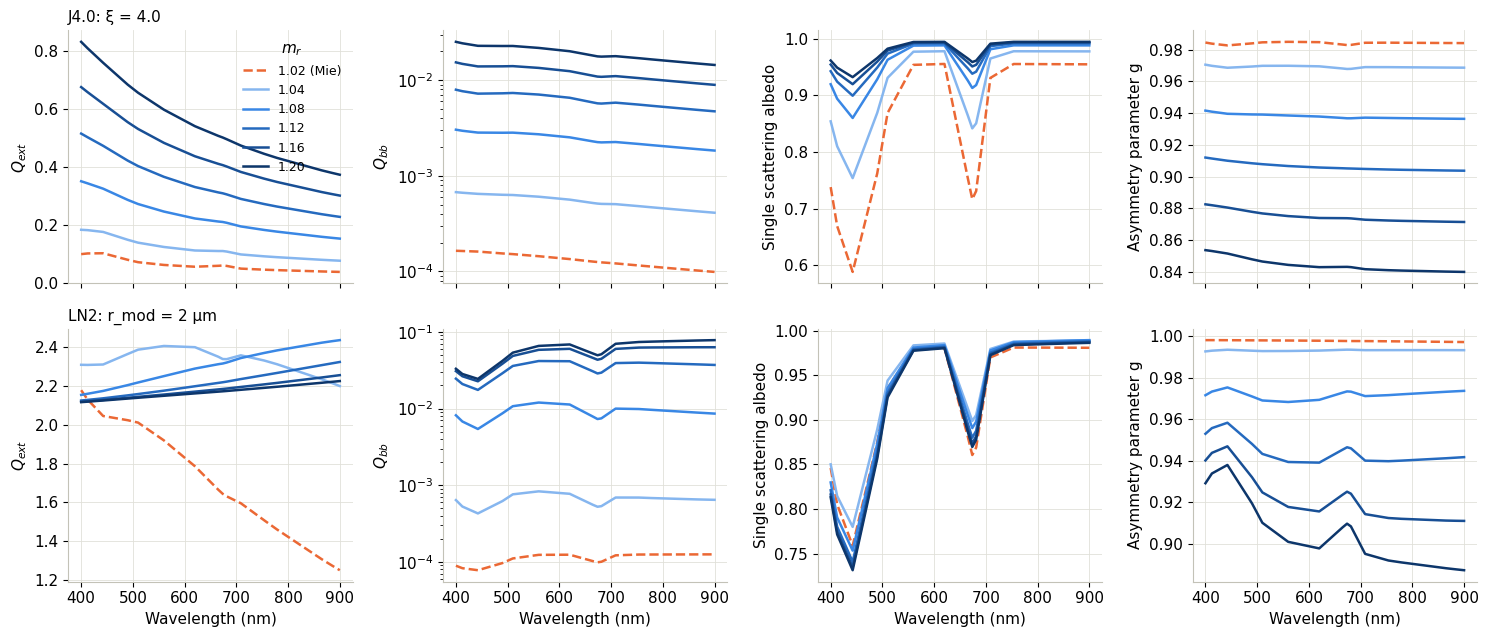

In [12]:
def mr_style(mr):
    if mr in mr_mie:
        return dict(color=MIE_COLOR, ls='--', label=f'{mr:.2f} (Mie)')
    return dict(color=MR_COLORS[mr_mopsmap.index(mr)], ls='-', label=f'{mr:.2f}')


panels = [('Qext', '$Q_{ext}$'), ('Qbb', '$Q_{bb}$'), ('ssa', 'Single scattering albedo'), ('g', 'Asymmetry parameter g')]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for i, p in enumerate(['J4.0', 'LN2']):
    for j, (v, label) in enumerate(panels):
        ax = axs[i, j]
        for mr in mr_all:
            ax.plot(wl, ds[v].sel(mr=mr, shape='pigment', psd=p), **mr_style(mr))
        ax.set_ylabel(label)
        if v == 'Qbb':
            ax.set_yscale('log')
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[1]:
    ax.set_xlabel('Wavelength (nm)')
axs[0, 0].legend(title='$m_r$', frameon=False)
plt.tight_layout()

### Sensitivity to $m_r$ for all size distributions

Non-absorbing particles at 560 nm.

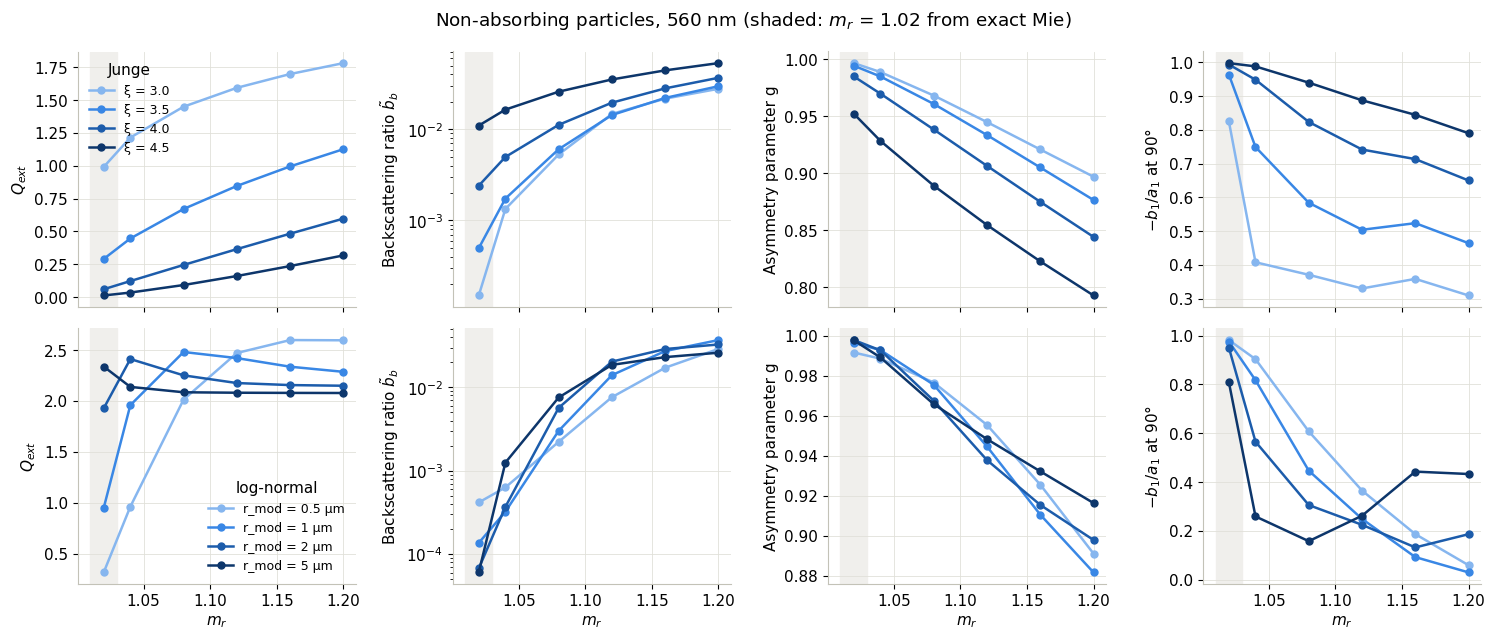

In [13]:
panels = [('Qext', '$Q_{ext}$'), ('bb_ratio', 'Backscattering ratio $\\tilde{b}_b$'),
          ('g', 'Asymmetry parameter g'), ('dolp90', '$-b_1/a_1$ at 90°')]
sub = ds.sel(shape='none', wl=560)
sub['dolp90'] = sub.dolp.sel(theta=90, method='nearest')
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for i, fam in enumerate(['Junge', 'log-normal']):
    ids = [p for p in psd_ids if psd_def[p][0] == fam]
    for j, (v, label) in enumerate(panels):
        ax = axs[i, j]
        for p, c in zip(ids, PSD_COLORS):
            y = sub[v].sel(psd=p)
            ax.plot(sub.mr, y, 'o-', ms=5, color=c, label=psd_def[p][1])
        ax.axvspan(1.01, 1.03, color='#f0efec', zorder=-1)
        ax.set_ylabel(label)
        if v == 'bb_ratio':
            ax.set_yscale('log')
    axs[i, 0].legend(title=fam, frameon=False)
for ax in axs[1]:
    ax.set_xlabel('$m_r$')
fig.suptitle('Non-absorbing particles, 560 nm (shaded: $m_r$ = 1.02 from exact Mie)')
plt.tight_layout()

### Scattering matrix

Phase function $a_1$ and the normalized elements $-b_1/a_1$ (degree of linear polarization for
unpolarized incident light), $a_3/a_1$ and $b_2/a_1$ at 560 nm, non-absorbing particles. For spheres,
$a_2 = a_1$ and $a_4 = a_3$.

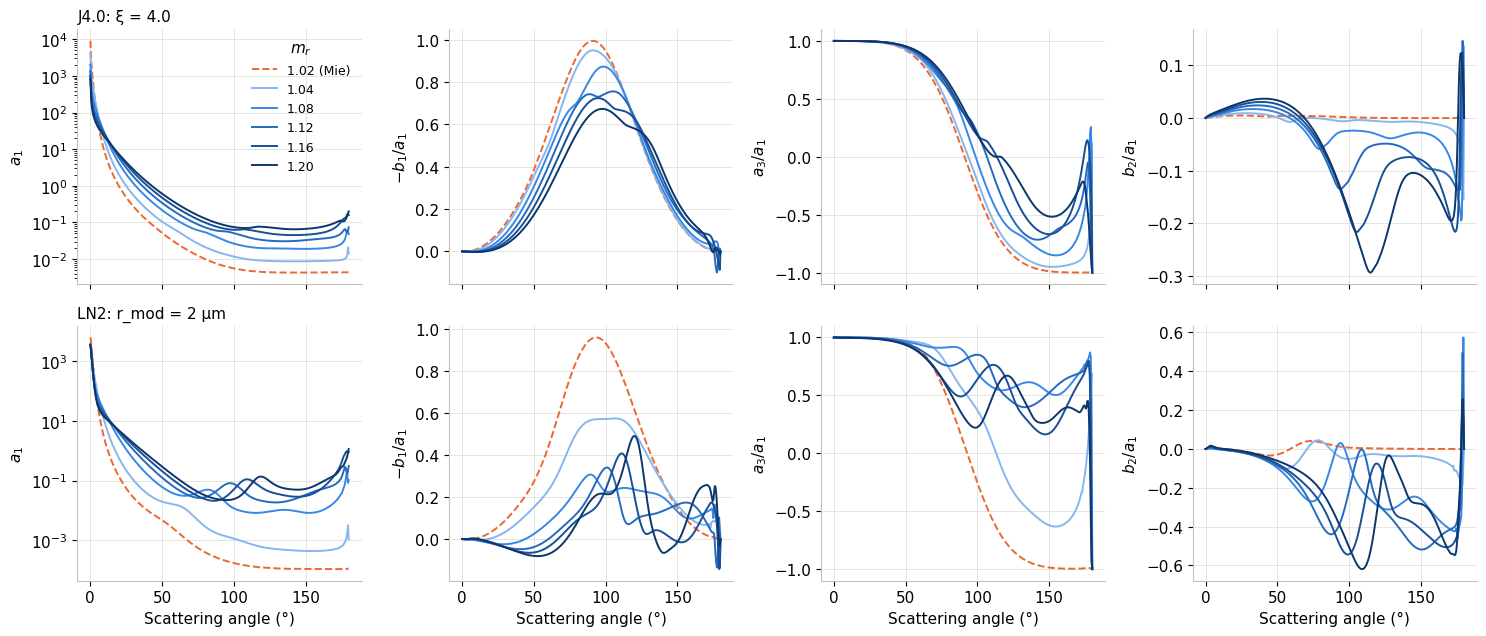

In [14]:
panels = [('a1', '$a_1$'), ('dolp', '$-b_1/a_1$'), ('a3', '$a_3/a_1$'), ('b2', '$b_2/a_1$')]
fig, axs = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for i, p in enumerate(['J4.0', 'LN2']):
    s = ds.sel(shape='none', psd=p, wl=560)
    a1 = s.F.sel(element='a1')
    for j, (v, label) in enumerate(panels):
        ax = axs[i, j]
        for mr in mr_all:
            if v == 'a1':
                y = a1.sel(mr=mr)
            elif v == 'dolp':
                y = s.dolp.sel(mr=mr)
            else:
                y = (s.F.sel(element=v) / a1).sel(mr=mr)
            ax.plot(s.theta, y, lw=1.4, **mr_style(mr))
        ax.set_ylabel(label)
    axs[i, 0].set_yscale('log')
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
for ax in axs[1]:
    ax.set_xlabel('Scattering angle (°)')
axs[0, 0].legend(title='$m_r$', frameon=False)
plt.tight_layout()

### Effect of the spectral imaginary part

$Q_{abs}$ and single scattering albedo for the four $m_i(\lambda)$ shapes at $m_r$ = 1.04 (solid)
and 1.16 (dashed).

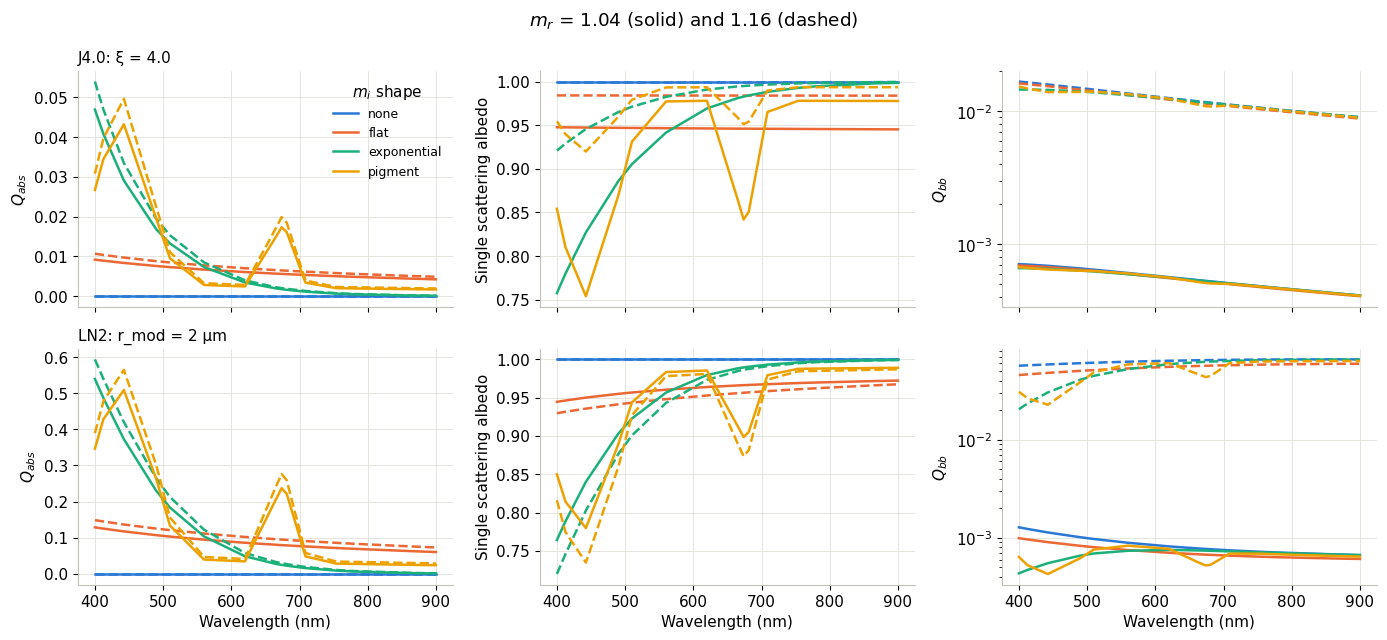

In [15]:
fig, axs = plt.subplots(2, 3, figsize=(14, 6.5), sharex=True)
for i, p in enumerate(['J4.0', 'LN2']):
    for s, c in zip(shapes, SHAPE_COLORS):
        for mr, ls in [(1.04, '-'), (1.16, '--')]:
            d = ds.sel(mr=mr, shape=s, psd=p)
            lab = s if mr == 1.04 else None
            axs[i, 0].plot(wl, d.Qabs, ls=ls, color=c, label=lab)
            axs[i, 1].plot(wl, d.ssa, ls=ls, color=c, label=lab)
            axs[i, 2].plot(wl, d.Qbb, ls=ls, color=c, label=lab)
    axs[i, 2].set_yscale('log')
    axs[i, 0].set_title(f'{p}: {psd_def[p][1]}', loc='left')
    axs[i, 0].set_ylabel('$Q_{abs}$')
    axs[i, 1].set_ylabel('Single scattering albedo')
    axs[i, 2].set_ylabel('$Q_{bb}$')
for ax in axs[1]:
    ax.set_xlabel('Wavelength (nm)')
axs[0, 0].legend(title='$m_i$ shape', frameon=False)
fig.suptitle('$m_r$ = 1.04 (solid) and 1.16 (dashed)')
plt.tight_layout()

### Summary table

Values at 560 nm for non-absorbing particles at $m_r$ = 1.02, 1.08 and 1.20, and normalized
sensitivity $\partial \ln X / \partial m_r$ between 1.04 and 1.20 (MOPSMAP nodes).

In [16]:
sub = ds.sel(shape='none', wl=560)
rows = {}
for v in ['Qext', 'bb_ratio', 'g']:
    for mr in [1.02, 1.08, 1.20]:
        rows[(v, f'{mr:.2f}')] = sub[v].sel(mr=mr).to_pandas()
    rows[(v, 'dln/dmr')] = np.log(sub[v].sel(mr=1.20) / sub[v].sel(mr=1.04)).to_pandas() / 0.16
summary = pd.DataFrame(rows).T
summary.columns = [f'{p}' for p in summary.columns]
summary.round(4)

J3.0     J3.5     J4.0     J4.5    LN0.5      LN1  \
Qext     1.02      0.9910   0.2908   0.0601   0.0129   0.3171   0.9498   
         1.08      1.4499   0.6713   0.2453   0.0924   2.0140   2.4809   
         1.20      1.7815   1.1264   0.5981   0.3179   2.5958   2.2862   
         dln/dmr   2.3929   5.7815   9.9085  13.7904   6.2005   0.9652   
bb_ratio 1.02      0.0002   0.0005   0.0024   0.0110   0.0004   0.0001   
         1.08      0.0053   0.0060   0.0112   0.0259   0.0022   0.0030   
         1.20      0.0278   0.0297   0.0367   0.0532   0.0289   0.0369   
         dln/dmr  18.9788  17.7482  12.5037   7.3435  23.9083  29.6268   
g        1.02      0.9968   0.9945   0.9851   0.9524   0.9917   0.9966   
         1.08      0.9684   0.9610   0.9386   0.8893   0.9767   0.9756   
         1.20      0.8971   0.8767   0.8443   0.7929   0.8912   0.8818   
         dln/dmr  -0.6092  -0.7286  -0.8675  -0.9871  -0.6487  -0.7420   

                      LN2      LN5  
Qext     1.02      1.9274   2.3380  
         1.08      2.2516   2.0855  
         1.20      2.1497   2.0784  
         dln/dmr  -0.7191  -0.1775  
bb_ratio 1.02      0.0001   0.0001  
         1.08      0.0057   0.0076  
         1.20      0.0327   0.0260  
         dln/dmr  28.0261  18.9749  
g        1.02      0.9979   0.9978  
         1.08      0.9676   0.9659  
         1.20      0.8980   0.9165  
         dln/dmr  -0.6274  -0.4775

## 6. Main results

At 560 nm, for non-absorbing particles (summary table and figures above):

* **Backscattering ratio** $\tilde{b}_b$ is the most sensitive parameter: it increases by about two
  orders of magnitude from $m_r$ = 1.02 ($\sim 10^{-4}$, up to 0.011 for the steepest power law) to 1.20
  (0.026 to 0.053), with $\partial \ln \tilde{b}_b / \partial m_r$ between 7 and 30.
* **$Q_{ext}$** of the power-law distributions increases with $m_r$, and more so for steeper
  distributions dominated by small particles ($\partial \ln Q_{ext} / \partial m_r$ from 2.4 for
  $\xi$ = 3 to 13.8 for $\xi$ = 4.5). For the log-normal distributions with $r_{mod} \ge$ 2 µm,
  $Q_{ext}$ stays between 2.1 and 2.4 for $m_r \ge$ 1.04 ($|\partial \ln Q_{ext} / \partial m_r| < 1$).
  At $m_r$ = 1.02, $Q_{ext}$ drops for $r_{mod} \le$ 2 µm (0.32, 0.95 and 1.93 vs 0.96, 1.95 and 2.4
  at 1.04): the phase shift $2x(m_r - 1)$ falls below the first extinction maximum.
* **Asymmetry parameter** decreases from 0.95–1.00 at $m_r$ = 1.02 to 0.79–0.92 at 1.20.
* **Polarization**: $-b_1/a_1$ at 90° is close to 1 at $m_r$ = 1.02 and decreases with $m_r$, with
  oscillations for the narrow log-normal distributions of large particles. At $m_r$ = 1.02, $a_3/a_1$ is
  close to $-1$ in the backward hemisphere and $b_2/a_1$ close to 0; both depart more and more from these
  values as $m_r$ increases.
* **Imaginary part**: the spectral shape of $m_i$ drives $Q_{abs}$ and the single scattering albedo
  (absorption bands at 442.5 and 675 nm for `pigment`). Its effect on the scattering matrix and $g$ is
  much smaller, but $Q_{bb}$ decreases in the absorption bands for the larger particles.
* **MOPSMAP limitations** for marine particles: interpolation between the $m_r$ nodes (1.00, 1.04, ...)
  makes values off the nodes, and $m_r$ = 1.02 in particular, unreliable; interpolation between
  $m_i$ = 0 and $5.4 \times 10^{-4}$ underestimates $Q_{abs}$ of large weakly absorbing particles by up
  to 14 %. Exact Mie computations are needed for those cases.

## 7. Saving the results

In [17]:
ofile = odir / 'sensitivity_marine_particles.nc'
out = ds.drop_vars('theta_rad').copy()
out['F'] = out.F.astype('float32')
out.attrs = dict(description='Sensitivity of the optical properties of marine particles (homogeneous spheres)',
                 refractive_index='relative to seawater, n_w = 1.34', wavelength='OLCI bands in vacuum (nm)',
                 radius_range_um=f'{r_min}-{r_max}', methods='mr=1.02: exact Mie (miepython); mr>=1.04: MOPSMAP')
out.to_netcdf(ofile, encoding={'F': {'zlib': True, 'complevel': 4}})
print(ofile, f'{ofile.stat().st_size / 1e6:.1f} MB')

/home/harmel/Dropbox/Dropbox/work/git/vrtc/mopsmap_tbx/scatmat/sensitivity/sensitivity_marine_particles.nc 29.5 MB
